In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Exercício 1

Considere a variável aleatória contínua $X$ com densidade

$$
f(x)=20x(1-x)^3, \qquad 0\leq x\leq 1,
$$

e $f(x)=0$ fora do intervalo $[0,1]$.

1. Utilizando o método de Aceitação-Rejeição (AR), gere uma amostra i.i.d. de tamanho $n$ da distribuição com densidade $f$. Utilize como distribuição proposta uma distribuição Uniforme em $[0,1]$.

   Para determinar a constante $M$ do método de Aceitação-Rejeição, aproxime numericamente o máximo de $f$ no intervalo $[0,1]$. Para isso, construa uma malha suficientemente fina utilizando `np.linspace`, avalie a função $f$ nos pontos dessa malha e utilize `np.max` para obter uma aproximação de

$$
M = \max_{0\leq x\leq 1} f(x).
$$

2. Faça um gráfico contendo a densidade teórica $f(x)$ e o histograma normalizado da amostra gerada. Compare visualmente a distribuição da amostra com a densidade teórica.

3. Para cada observação gerada, registre o número de tentativas necessárias até ocorrer a primeira aceitação.

   a. Determine teoricamente a probabilidade de aceitação do método AR.

   b. Determine o número esperado de tentativas até a primeira aceitação.

   c. Compare a média empírica do número de tentativas com o valor esperado teoricamente.

   d. Determine a distribuição teórica do número de tentativas até a primeira aceitação e compare-a com a distribuição empírica obtida na simulação.

In [4]:
def f(x):
   return 20*x*((1-x)**3)

(array([0.84574472, 1.64514726, 2.08539794, 2.05064131, 1.81893042,
        1.3670942 , 0.83415918, 0.59086275, 0.26646751, 0.08109881]),
 array([0.00218886, 0.08850332, 0.17481779, 0.26113225, 0.34744671,
        0.43376117, 0.52007563, 0.60639009, 0.69270455, 0.77901902,
        0.86533348]),
 <BarContainer object of 10 artists>)

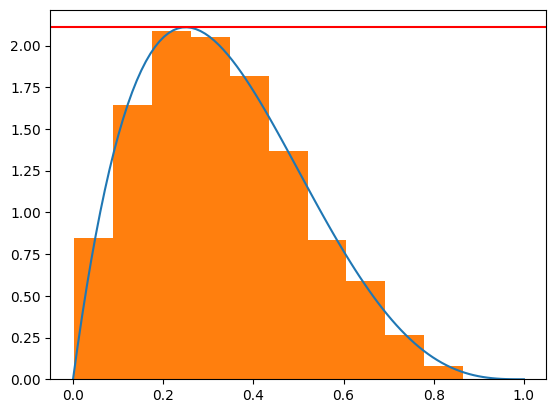

In [5]:
x = np.linspace(0,1, 100)
amostra = []
amostra_tentativas = []
n = 1000
c = np.max(f(x))
for i in range(n):
  y = 1
  U = 1
  tryes = 0
  while c*U > f(y):
    tryes += 1
    U = np.random.uniform()
    y = np.random.uniform()
  X = y
  amostra.append(X)
  amostra_tentativas.append(tryes)
plt.plot(x, f(x))
plt.axhline(c, color="Red")
plt.hist(amostra, density = True)







2.109232163060931
2.146


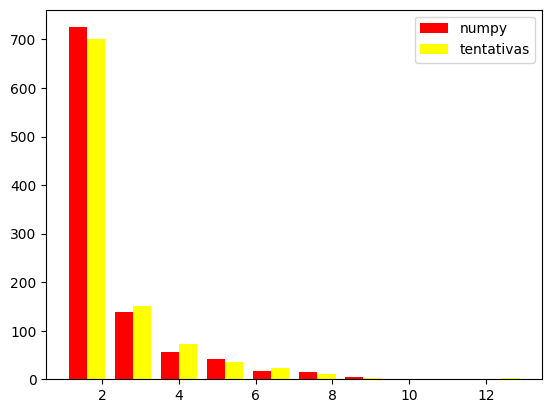

In [16]:
esperanca = np.mean(amostra_tentativas)
print(c)
print(esperanca)
amostra_numpy = np.random.geometric(1/c, size=n)
plt.hist([amostra_numpy, amostra_tentativas], bins = 10, label=["numpy", "tentativas"], color=["red", "yellow"])

plt.legend()